<a href="https://colab.research.google.com/github/NisalJayaweera/EN3160-Neural-Networks/blob/main/EN3160_Q3_ResNet18_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 Assignment 3 — Question 3: ResNet18 Transfer Learning

**Task:** Classify the Hymenoptera (ants vs bees) dataset using ImageNet-1K-pretrained ResNet18 in two settings: **(a) full fine-tuning** and **(b) frozen-backbone feature extraction**. Compare results using the same data, preprocessing, epochs, optimizer family, and evaluation protocol.

**Run in Google Colab:** Runtime → Change runtime type → T4 GPU (if available), then Runtime → Run all. All metrics below are generated from execution; no results are assumed in advance. Dataset and pretrained weights require internet access on first run.

In [1]:
import copy, random, time, tarfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EPOCHS = 10
BATCH_SIZE = 16
LR = 1e-3
print('Device:', DEVICE)
print('PyTorch:', torch.__version__)

Device: cuda
PyTorch: 2.11.0+cu130


## 1. Download and inspect the Hymenoptera dataset

Use the sample dataset linked by the official PyTorch transfer-learning tutorial. Its two classes are `ants` and `bees`, with `train` and `val` splits. Here the tutorial's **validation split is used for evaluation**; it is not a separate held-out test set. No model selection or hyperparameter tuning is performed using this split.

In [2]:
DATA_ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
DATA_DIR = DATA_ROOT / 'hymenoptera_data'
ARCHIVE = DATA_ROOT / 'hymenoptera_data.zip'
URL = 'https://download.pytorch.org/tutorial/hymenoptera_data.zip'
if not (DATA_DIR / 'train').exists() or not (DATA_DIR / 'val').exists():
    print('Downloading dataset...')
    urllib.request.urlretrieve(URL, ARCHIVE)
    import zipfile
    with zipfile.ZipFile(ARCHIVE) as z:
        # Only extract safe paths (avoid traversal from malformed archives).
        for member in z.infolist():
            target = (DATA_ROOT / member.filename).resolve()
            if not target.is_relative_to(DATA_ROOT.resolve()):
                raise ValueError('Unsafe archive member')
        z.extractall(DATA_ROOT)
print('Dataset:', DATA_DIR)
print('Training images:', len(datasets.ImageFolder(DATA_DIR / 'train')))
print('Evaluation images:', len(datasets.ImageFolder(DATA_DIR / 'val')))

Dataset: /content/hymenoptera_data
Training images: 244
Evaluation images: 153


## 2. Shared preprocessing and loaders

Both models use **the same deterministic resizing and ImageNet normalization**. No random data augmentation is applied, so differences in training do not arise from different image transformations. The pretrained ImageNet-1K weights expect RGB images normalized with ImageNet mean and standard deviation.

In [3]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
train_ds = datasets.ImageFolder(DATA_DIR / 'train', transform=preprocess)
val_ds = datasets.ImageFolder(DATA_DIR / 'val', transform=preprocess)
assert train_ds.classes == val_ds.classes == ['ants', 'bees']
CLASS_NAMES = train_ds.classes

def train_loader():
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=generator,
                      num_workers=2, pin_memory=(DEVICE.type == 'cuda'))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=2, pin_memory=(DEVICE.type == 'cuda'))
print('Classes:', CLASS_NAMES)
print('Train:', len(train_ds), '| Validation:', len(val_ds))

Classes: ['ants', 'bees']
Train: 244 | Validation: 153


## 3. Construct the two ResNet18 models

**Fine-tuning:** replace the final fully connected layer with a 2-class classifier and train **all** parameters.

**Feature extraction:** use the same ImageNet-pretrained backbone, freeze all pretrained parameters, and train **only** the newly initialized 2-class classifier. In feature-extraction mode the frozen backbone is kept in evaluation mode to avoid updating batch-normalization running statistics.

In [4]:
def build_model(mode):
    assert mode in ('fine_tuning', 'feature_extraction')
    model = models.resnet18(weights=weights)
    if mode == 'feature_extraction':
        for p in model.parameters():
            p.requires_grad = False
    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, len(CLASS_NAMES))
    return model.to(DEVICE)

def count_params(model):
    return sum(p.numel() for p in model.parameters()), sum(p.numel() for p in model.parameters() if p.requires_grad)

for mode in ('fine_tuning', 'feature_extraction'):
    torch.manual_seed(SEED)
    model = build_model(mode)
    total, trainable = count_params(model)
    print(f'{mode}: total parameters={total:,}, trainable parameters={trainable:,}')
    del model
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 222MB/s]


fine_tuning: total parameters=11,177,538, trainable parameters=11,177,538
feature_extraction: total parameters=11,177,538, trainable parameters=1,026


## 4. Training and evaluation

Both approaches use Adam, cross-entropy loss, batch size 16, and 10 epochs. Only parameters with `requires_grad=True` are passed to the optimizer. Training accuracy/loss are computed from minibatches during training; validation metrics are measured in evaluation mode after each epoch.

**Note:** This is a small dataset, so results may vary by seed, hardware, and optimization settings. Validation accuracy is not an unbiased estimate of performance on an additional unseen test set.

In [5]:
criterion = nn.CrossEntropyLoss()

def evaluate(model, loader, return_predictions=False):
    model.eval()
    running_loss, correct, count = 0.0, 0, 0
    truth, predictions = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = model(images)
            running_loss += criterion(logits, labels).item() * labels.size(0)
            predicted = logits.argmax(dim=1)
            correct += (predicted == labels).sum().item()
            count += labels.size(0)
            if return_predictions:
                truth.extend(labels.cpu().tolist())
                predictions.extend(predicted.cpu().tolist())
    result = (running_loss/count, 100.0*correct/count)
    return (*result, truth, predictions) if return_predictions else result

def run_experiment(mode, label):
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    model = build_model(mode)
    optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=LR)
    loader = train_loader()
    history = []
    start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        if mode == 'feature_extraction':
            # Keep frozen backbone and its BatchNorm statistics fixed.
            model.eval()
            model.fc.train()
        loss_sum, correct, count = 0.0, 0, 0
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            count += labels.size(0)
        val_loss, val_acc = evaluate(model, val_loader)
        record = dict(model=label, epoch=epoch, train_loss=loss_sum/count,
                      train_accuracy=100.0*correct/count, val_loss=val_loss,
                      val_accuracy=val_acc)
        history.append(record)
        print(f'{label:18s} | epoch {epoch:02d}/{EPOCHS} | '
              f'train {record["train_accuracy"]:.2f}% / {record["train_loss"]:.4f} | '
              f'val {val_acc:.2f}% / {val_loss:.4f}')
    duration = time.perf_counter() - start
    print(f'{label}: total training time {duration:.1f} s')
    return model, pd.DataFrame(history), duration

## 5. Execute both training experiments

This cell performs the complete 10-epoch training for each approach. Training may take several minutes, particularly on CPU.

In [6]:
fine_model, fine_history, fine_seconds = run_experiment('fine_tuning', 'Fine-tuning')
feature_model, feature_history, feature_seconds = run_experiment('feature_extraction', 'Feature extraction')
history = pd.concat([fine_history, feature_history], ignore_index=True)

Fine-tuning        | epoch 01/10 | train 68.03% / 0.8802 | val 60.78% / 11.7786
Fine-tuning        | epoch 02/10 | train 82.79% / 0.4201 | val 70.59% / 1.3358
Fine-tuning        | epoch 03/10 | train 82.38% / 0.3862 | val 76.47% / 0.6003
Fine-tuning        | epoch 04/10 | train 87.70% / 0.3154 | val 84.97% / 0.4136
Fine-tuning        | epoch 05/10 | train 93.85% / 0.1632 | val 78.43% / 0.6057
Fine-tuning        | epoch 06/10 | train 96.31% / 0.0998 | val 72.55% / 1.0267
Fine-tuning        | epoch 07/10 | train 96.72% / 0.1003 | val 72.55% / 0.8296
Fine-tuning        | epoch 08/10 | train 90.98% / 0.2082 | val 72.55% / 0.8263
Fine-tuning        | epoch 09/10 | train 94.26% / 0.1701 | val 75.82% / 1.4221
Fine-tuning        | epoch 10/10 | train 96.72% / 0.0945 | val 78.43% / 0.5509
Fine-tuning: total training time 26.0 s
Feature extraction | epoch 01/10 | train 67.21% / 0.5689 | val 92.81% / 0.3726
Feature extraction | epoch 02/10 | train 96.31% / 0.2706 | val 94.12% / 0.2447
Feature ext

## 6. Compare accuracy and loss across epochs

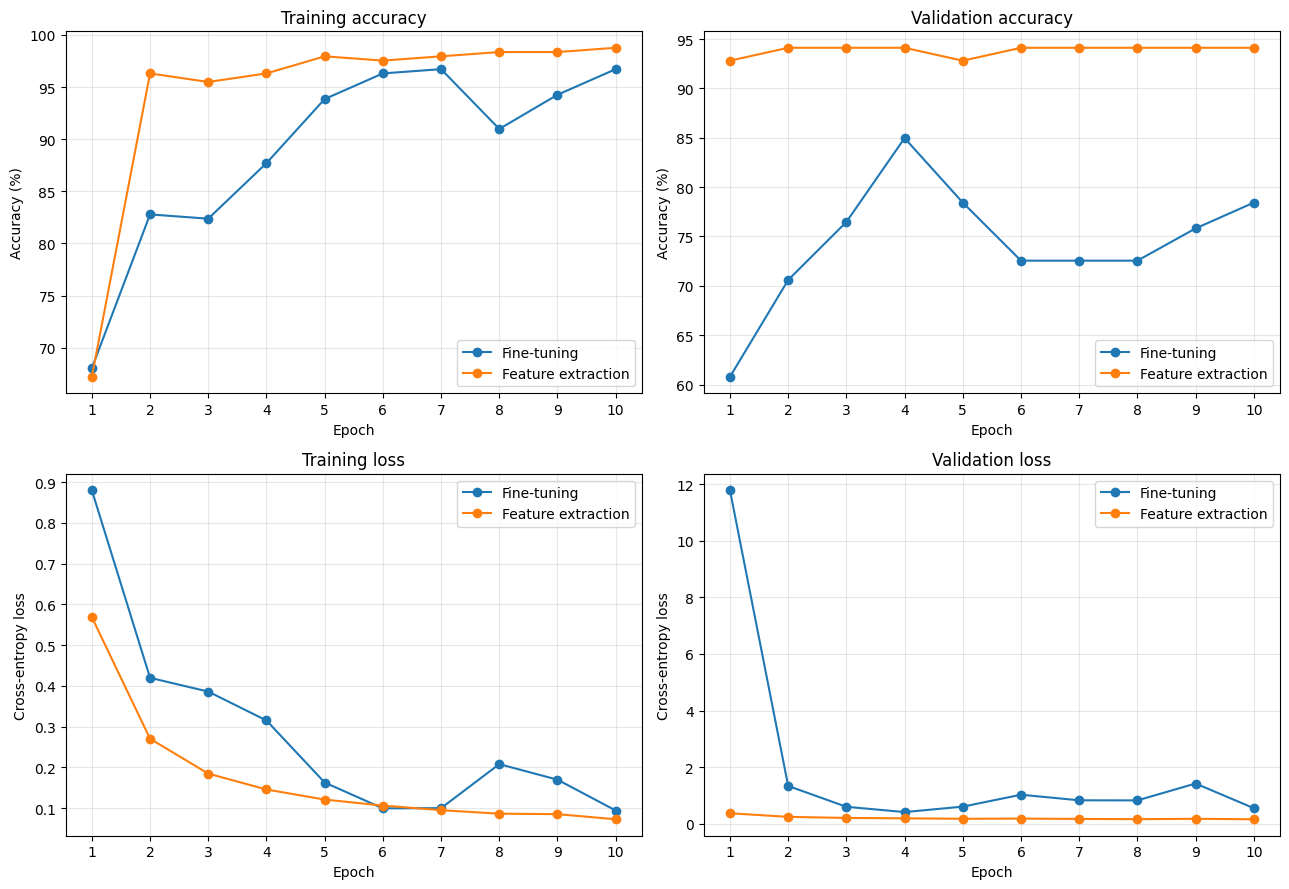

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
metrics = [('train_accuracy', 'Training accuracy', 'Accuracy (%)'),
           ('val_accuracy', 'Validation accuracy', 'Accuracy (%)'),
           ('train_loss', 'Training loss', 'Cross-entropy loss'),
           ('val_loss', 'Validation loss', 'Cross-entropy loss')]
for ax, (column, title, ylabel) in zip(axes.flat, metrics):
    for name, group in history.groupby('model', sort=False):
        ax.plot(group.epoch, group[column], marker='o', label=name)
    ax.set(title=title, xlabel='Epoch', ylabel=ylabel)
    ax.set_xticks(range(1, EPOCHS + 1))
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

## 7. Confusion matrices and class-wise performance

The matrices use the **entire validation split**, not the training images. Rows represent true labels; columns represent predictions.

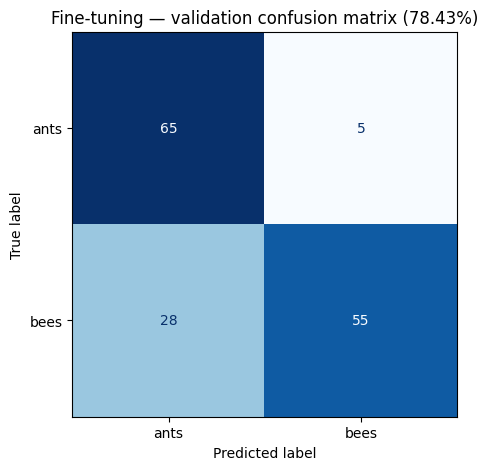


Fine-tuning — class-wise validation metrics:
              precision    recall  f1-score   support

        ants       0.70      0.93      0.80        70
        bees       0.92      0.66      0.77        83

    accuracy                           0.78       153
   macro avg       0.81      0.80      0.78       153
weighted avg       0.82      0.78      0.78       153



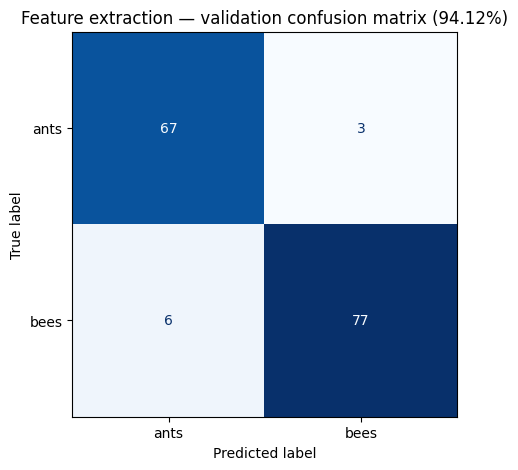


Feature extraction — class-wise validation metrics:
              precision    recall  f1-score   support

        ants       0.92      0.96      0.94        70
        bees       0.96      0.93      0.94        83

    accuracy                           0.94       153
   macro avg       0.94      0.94      0.94       153
weighted avg       0.94      0.94      0.94       153



In [8]:
for name, model in [('Fine-tuning', fine_model), ('Feature extraction', feature_model)]:
    loss, accuracy, truth, pred = evaluate(model, val_loader, return_predictions=True)
    cm = confusion_matrix(truth, pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(f'{name} — validation confusion matrix ({accuracy:.2f}%)')
    plt.show()
    print(f'\n{name} — class-wise validation metrics:')
    print(classification_report(truth, pred, target_names=CLASS_NAMES, zero_division=0))

## 8. Final results table and exported figures

All figures and CSV files are saved under `results/q3/`. In Colab, download this folder or its individual files before the session expires. The saved notebook also retains inline figures when committed after execution.

             model  train_accuracy  val_accuracy  train_loss  val_loss  training_seconds
       Fine-tuning         96.7213       78.4314      0.0945    0.5509           26.0040
Feature extraction         98.7705       94.1176      0.0730    0.1594           23.3961


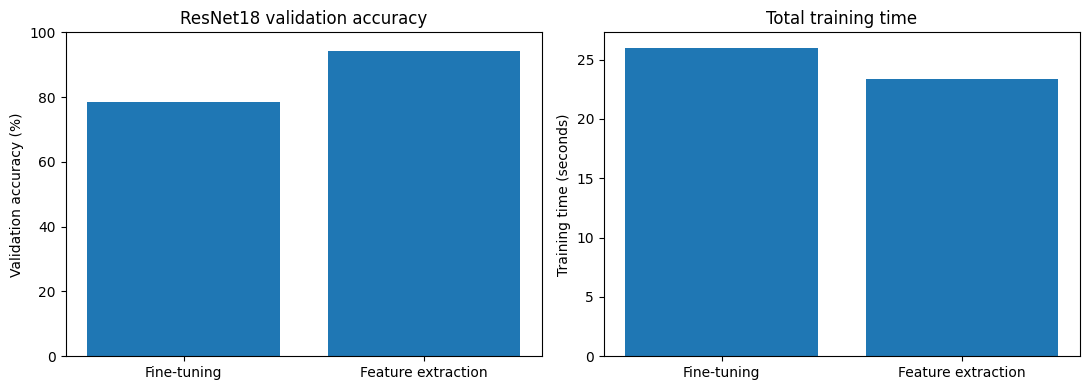

Saved to: /content/results/q3


In [9]:
out = Path('results/q3')
out.mkdir(parents=True, exist_ok=True)
history.to_csv(out/'resnet18_training_history.csv', index=False)
summary = history[history.epoch == EPOCHS].copy()
summary['training_seconds'] = summary['model'].map({'Fine-tuning': fine_seconds,
                                                   'Feature extraction': feature_seconds})
summary = summary[['model', 'train_accuracy', 'val_accuracy', 'train_loss',
                   'val_loss', 'training_seconds']]
summary.to_csv(out/'resnet18_summary.csv', index=False)
print(summary.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(summary['model'], summary['val_accuracy'])
axes[0].set_ylabel('Validation accuracy (%)')
axes[0].set_ylim(0, 100)
axes[0].set_title('ResNet18 validation accuracy')
axes[1].bar(summary['model'], summary['training_seconds'])
axes[1].set_ylabel('Training time (seconds)')
axes[1].set_title('Total training time')
fig.tight_layout()
fig.savefig(out/'accuracy_and_training_time.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved to:', out.resolve())

## Discussion – Question 3: ResNet18 Transfer Learning

In this experiment, two transfer learning approaches were compared using an ImageNet-pretrained ResNet18 model to classify ants and bees from the Hymenoptera dataset. In the fine-tuning approach, all layers of the pretrained network were updated during training, while in feature extraction, the pretrained layers were frozen and only the final classification layer was trained. Both models were trained for 10 epochs using the same dataset, batch size, optimizer, and learning rate.

After 10 epochs, the fine-tuning approach achieved a training accuracy of **96.72%** and a validation accuracy of **78.43%**, whereas feature extraction achieved **98.77%** training accuracy and **94.12%** validation accuracy. Feature extraction therefore performed considerably better, with a validation accuracy improvement of approximately **15.69 percentage points**.

The training and validation curves show that fine-tuning improved its training performance over the 10 epochs, but its validation accuracy fluctuated noticeably. Although the training loss decreased to 0.0945, the final validation loss remained relatively high at 0.5509. The large difference between training and validation accuracy, approximately 18.29 percentage points, suggests that the fine-tuned model did not generalize well to the validation images. In contrast, feature extraction produced more stable validation results, with a final validation loss of 0.1594 and an accuracy gap of only 4.65 percentage points.

The confusion matrices and classification reports also support these observations. Fine-tuning achieved a recall of 93% for ants but only 66% for bees, suggesting that it had more difficulty identifying bee images correctly. Feature extraction performed more consistently across both classes, achieving recall values of 96% for ants and 93% for bees.

One possible explanation is the relatively small size of the Hymenoptera training dataset, which contains only 244 images. Updating all the parameters of ResNet18 on such a limited dataset may disturb some of the useful features learned during ImageNet pretraining. By freezing the pretrained backbone, feature extraction preserves these features and only learns a new classifier for the two target classes. This may explain its better generalization in this experiment.

Feature extraction was also slightly faster, taking approximately **23.40 seconds**, compared with **26.00 seconds** for fine-tuning. It required training only 1,026 parameters, whereas fine-tuning updated all 11.18 million parameters.

Overall, feature extraction was the more effective approach under the conditions tested, achieving higher validation accuracy, lower validation loss, and a shorter training time. However, this does not mean that feature extraction is always better than fine-tuning. With a larger dataset, data augmentation, or a smaller learning rate for the pretrained layers, fine-tuning might achieve better results. The experiment demonstrates that preserving pretrained features can be particularly useful when working with a limited amount of training data.